In [38]:
import numpy as np

def research(x):
    return 200_000 * np.log(1+x) / np.log(1 + 100)

def scale(x):
    return (7/100)*x

def speed(x):
    # highest speed = 0.9
    # lowest receives 0.1
    # Goal: slightly beat avg Nash
    if x == 100:
        return 0.9
    if x == 99:
        return 0.8
    if x == 0:
        return 0.1
    
    return round((0.8/100)*x + 0.1,1)


def PnL(pct_research, pct_scale, pct_speed):
    budget_used = pct_research+pct_scale+pct_speed
    res = research(pct_research)
    sca = scale(pct_scale)
    spe = speed(pct_speed)
    
    #print(f"Testing: ({pct_research,pct_scale,pct_speed})  | PnL = {(res*sca*spe)-budget_used}")
    
    return (res*sca*spe)-budget_used

best = -1
best_d = (0,0,0)
for r in range(1,100):
    for sc in range (1, 100-r):
        for sp in range(0,100-r-sc):
            profit = PnL(r,sc,sp)
            #print(profit)
            if profit > best:
                best = profit
                best_d = (r,sp,sc)

print(best)
print(best_d)
            
            

175260.25427248445
(17, 32, 50)


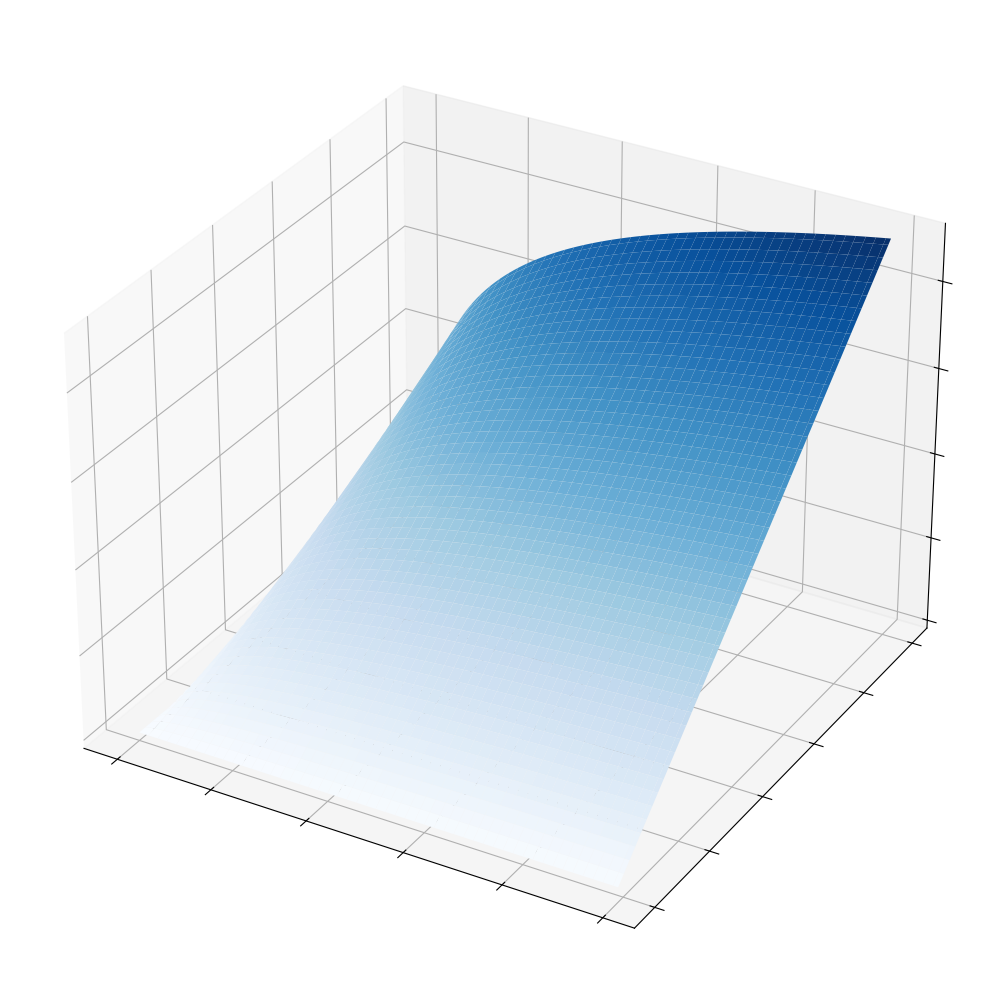

In [34]:
import matplotlib.pyplot as plt
import numpy as np

from matplotlib import cm

plt.style.use('_mpl-gallery')

# Make data
X = np.arange(0, 100, 1)
Y = np.arange(0, 100, 1)
X, Y = np.meshgrid(X, Y)
Z = PnL(X, Y, 70)

# Plot the surface
fig, ax = plt.subplots(subplot_kw={"projection": "3d"}, figsize=(10,10))
ax.plot_surface(X, Y, Z, vmin=Z.min() * 2, cmap=cm.Blues)

ax.set(xticklabels=[],
       yticklabels=[],
       zticklabels=[])


plt.show()

Best Outcome:
156665.9982049386
(16, 35, 48)